# Student performance: exploratory data analysis

**Question:** what separates students who pass from students who fail, and where should a university look first to help?

Data: 1,000 course results of 244 students in 10 majors over 4 semesters (sample course data, cleaned by `src/prepare_data.py`).
Note on the columns: `grade_points` is the grade point of that single course result (it is called "GPA (Semester)" in the source file), and it maps one to one onto the letter grade.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook", palette=["#14213D", "#2A9D8F", "#F4A259", "#D1495B", "#6B7785"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = "../images/"

df = pd.read_csv("../data/student_performance.csv")
order = ["A", "B", "C", "D", "F"]
sem_order = ["Fall 2023", "Spring 2024", "Fall 2024", "Spring 2025"]
df["grade"] = pd.Categorical(df["grade"], order, ordered=True)
df["semester"] = pd.Categorical(df["semester"], sem_order, ordered=True)
df["failed"] = (df["grade"] == "F").astype(int)
print(df.shape); df.head()

(1000, 10)


,student_id,gender,major,semester,course,credits,grade,grade_points,attendance_pct,failed
0,STU-7001,Male,Mathematics,Fall 2023,Linear Algebra,3,A,3.98,96,0
1,STU-7001,Male,Mathematics,Spring 2024,Abstract Algebra,3,B,2.90,80,0
2,STU-7001,Male,Mathematics,Fall 2024,Calculus II,4,A,3.83,96,0
3,STU-7001,Male,Mathematics,Spring 2025,Calculus II,3,F,0.00,37,1
4,STU-7001,Male,Mathematics,Spring 2025,Real Analysis,4,B,2.93,92,0


## 1. Data quality

In [2]:
quality = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()})
display(quality)
print("duplicate rows:", df.duplicated().sum())
print("grade points range per grade:"); display(df.groupby("grade", observed=True).grade_points.agg(["min", "max", "count"]))

,dtype,missing,unique
student_id,str,0,244
gender,str,0,2
major,str,0,10
semester,category,0,4
course,str,0,79
credits,int64,0,2
grade,category,0,5
grade_points,float64,0,222
attendance_pct,int64,0,68
failed,int64,0,2


duplicate rows: 0
grade points range per grade:


,min,max,count
grade,,,
A,3.7,4.00,198
B,2.7,3.30,354
C,1.7,2.30,254
D,0.7,1.28,110
F,0.0,0.29,84


The data is complete and consistent: no missing values, no duplicates, and every letter grade sits in its own grade-point band, so `grade_points` carries no information beyond the grade. I use the letter grade as the outcome and attendance as the main explanatory variable.

## 2. Grade distribution

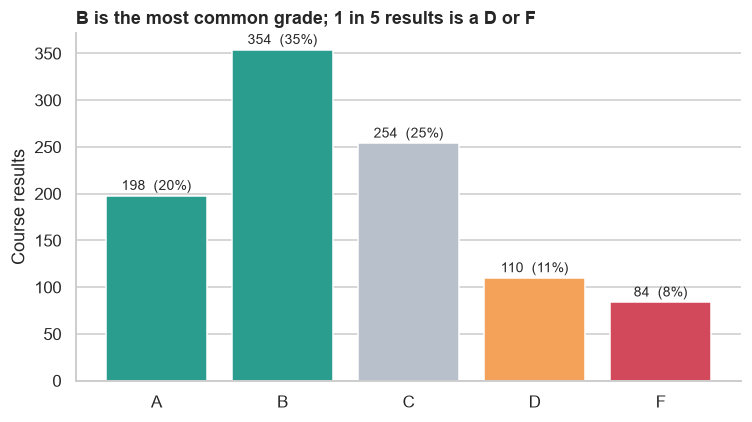

pass rate (A-D): 91.6%   fail rate (F): 8.4%   D or F: 19.4%


In [3]:
dist = df["grade"].value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(dist.index.astype(str), dist.values, color=["#2A9D8F", "#2A9D8F", "#B8C0CC", "#F4A259", "#D1495B"])
for b, v in zip(bars, dist.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 6, f"{v}  ({v/len(df):.0%})", ha="center", fontsize=9)
ax.set_title("B is the most common grade; 1 in 5 results is a D or F", loc="left", fontweight="bold")
ax.set_ylabel("Course results"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(IMG + "01_grade_distribution.png", dpi=150); plt.show()
print(f"pass rate (A-D): {1 - df.failed.mean():.1%}   fail rate (F): {df.failed.mean():.1%}   D or F: {(df.grade.isin(['D','F'])).mean():.1%}")

## 3. Attendance is the strongest signal

Spearman correlation attendance vs grade points: 0.85 (p = 7.1e-278)
credit hours vs grade points: 0.01


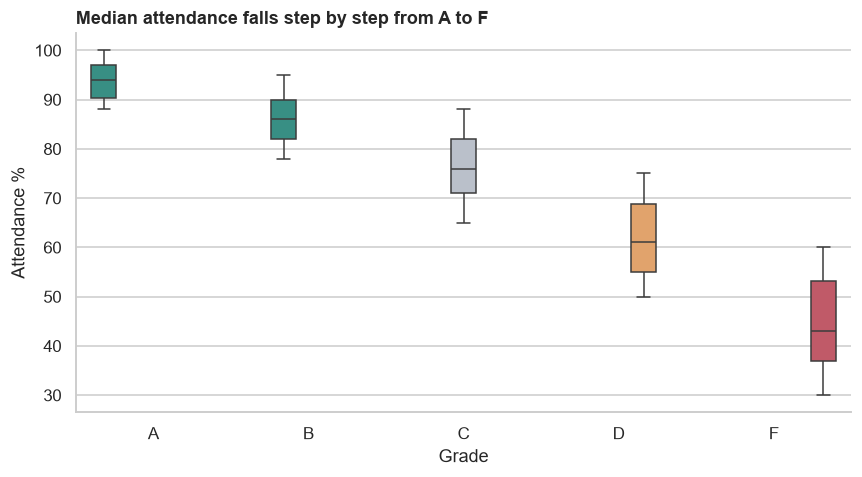

,count,mean,50%,min,max
grade,,,,,
A,198.0,93.6,94.0,88.0,100.0
B,354.0,86.1,86.0,78.0,95.0
C,254.0,76.2,76.0,65.0,88.0
D,110.0,62.0,61.0,50.0,75.0
F,84.0,44.6,43.0,30.0,60.0


In [4]:
r, p = stats.spearmanr(df.attendance_pct, df.grade_points)
print(f"Spearman correlation attendance vs grade points: {r:.2f} (p = {p:.1e})")
print("credit hours vs grade points:", round(stats.spearmanr(df.credits, df.grade_points)[0], 2))
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="grade", y="attendance_pct", order=order, ax=ax, palette=["#2A9D8F", "#2A9D8F", "#B8C0CC", "#F4A259", "#D1495B"], hue="grade", legend=False, fliersize=2)
ax.set_title("Median attendance falls step by step from A to F", loc="left", fontweight="bold")
ax.set_xlabel("Grade"); ax.set_ylabel("Attendance %")
fig.tight_layout(); fig.savefig(IMG + "02_attendance_by_grade.png", dpi=150); plt.show()
display(df.groupby("grade", observed=True).attendance_pct.describe().round(1)[["count", "mean", "50%", "min", "max"]])

,results,fail_rate,d_or_f,avg_grade_points
att_band,,,,
<=50,59,0.966,1.000,0.100
51-60,72,0.375,1.000,0.651
61-70,103,0.000,0.417,1.584
71-80,194,0.000,0.103,2.212
81-90,337,0.000,0.000,2.892
91-100,235,0.000,0.000,3.581


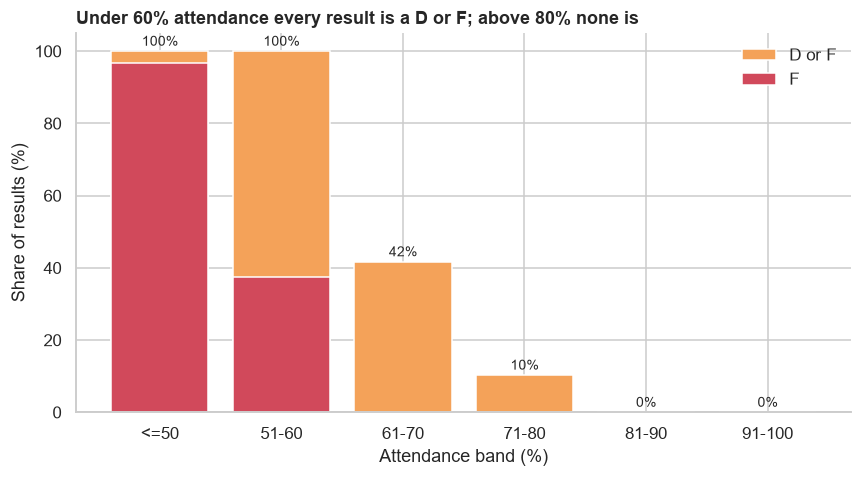

In [5]:
bins = [0, 50, 60, 70, 80, 90, 100]
labels = ["<=50", "51-60", "61-70", "71-80", "81-90", "91-100"]
df["att_band"] = pd.cut(df.attendance_pct, bins=bins, labels=labels, include_lowest=True)
band = df.groupby("att_band", observed=True).agg(results=("failed", "size"), fail_rate=("failed", "mean"),
        d_or_f=("grade", lambda s: s.isin(["D", "F"]).mean()), avg_grade_points=("grade_points", "mean")).round(3)
display(band)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(band.index.astype(str), band.d_or_f * 100, color="#F4A259", label="D or F")
ax.bar(band.index.astype(str), band.fail_rate * 100, color="#D1495B", label="F")
for i, (a, b) in enumerate(zip(band.d_or_f, band.fail_rate)):
    ax.text(i, a * 100 + 1.5, f"{a:.0%}", ha="center", fontsize=9)
ax.set_title("Under 60% attendance every result is a D or F; above 80% none is", loc="left", fontweight="bold")
ax.set_xlabel("Attendance band (%)"); ax.set_ylabel("Share of results (%)"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(IMG + "03_risk_by_attendance.png", dpi=150); plt.show()

The relationship is not a gentle slope but a set of thresholds: an F only ever appears at 60% attendance or below, every result at 60% or below is a D or F, and above 80% there is no D or F at all. That makes attendance a practical early-warning indicator.

## 4. Majors

,results,students,avg_attendance,avg_grade_points,fail_rate
major,,,,,
Mathematics,101,24,80.80,2.60,0.05
Economics,96,23,81.30,2.57,0.05
English Literature,96,23,80.02,2.54,0.06
Computer Science,78,19,78.18,2.43,0.06
Mechanical Engineering,107,26,78.39,2.40,0.07
Business Administration,120,29,78.45,2.49,0.08
Chemistry,110,27,78.09,2.44,0.09
Psychology,84,21,78.12,2.45,0.10
Nursing,86,22,79.95,2.49,0.12


Chi-square test, fail rate differs by major: chi2 = 10.2, p = 0.338
Kruskal-Wallis, grade points differ by major: H = 8.5, p = 0.480


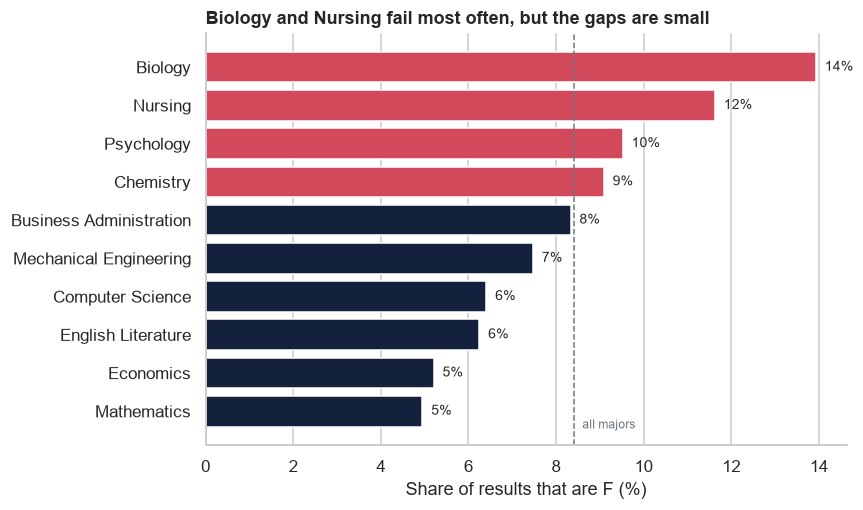

In [6]:
maj = df.groupby("major").agg(results=("failed", "size"), students=("student_id", "nunique"), avg_attendance=("attendance_pct", "mean"),
        avg_grade_points=("grade_points", "mean"), fail_rate=("failed", "mean")).sort_values("fail_rate")
display(maj.round(2))
chi, p, *_ = stats.chi2_contingency(pd.crosstab(df.major, df.failed))
print(f"Chi-square test, fail rate differs by major: chi2 = {chi:.1f}, p = {p:.3f}")
kw = stats.kruskal(*[g.grade_points.values for _, g in df.groupby("major")])
print(f"Kruskal-Wallis, grade points differ by major: H = {kw.statistic:.1f}, p = {kw.pvalue:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.8))
colors = ["#D1495B" if v > df.failed.mean() else "#14213D" for v in maj.fail_rate]
ax.barh(maj.index, maj.fail_rate * 100, color=colors)
ax.axvline(df.failed.mean() * 100, color="#6B7785", ls="--", lw=1); ax.text(df.failed.mean() * 100 + .2, -0.45, "all majors", fontsize=8, color="#6B7785")
for y, v in enumerate(maj.fail_rate):
    ax.text(v * 100 + .2, y, f"{v:.0%}", va="center", fontsize=9)
ax.set_title("Biology and Nursing fail most often, but the gaps are small", loc="left", fontweight="bold"); ax.set_xlabel("Share of results that are F (%)"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(IMG + "04_fail_rate_by_major.png", dpi=150); plt.show()

Neither test shows a significant difference between majors (p > 0.3 for both), so I would not single out a major from this data alone. Biology stands out descriptively (highest fail rate, lowest attendance). The next cell looks at whether attendance lines up with the fail rate across majors.

correlation between a major's average attendance and its fail rate (only 10 points, suggestive): -0.68


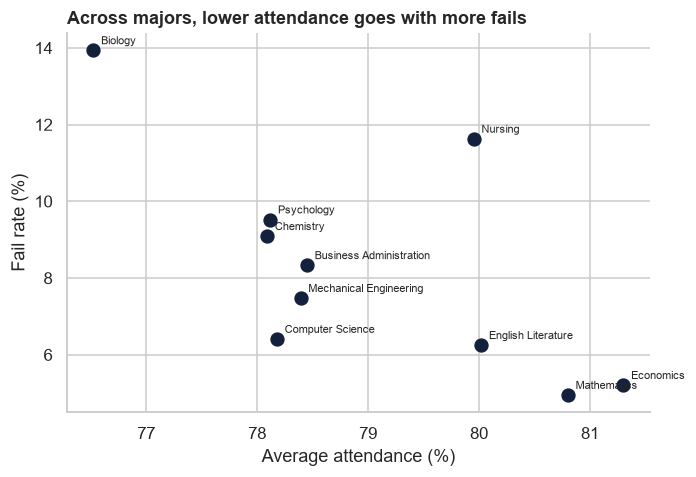

In [7]:
print("correlation between a major's average attendance and its fail rate (only 10 points, suggestive):", round(maj.avg_attendance.corr(maj.fail_rate), 2))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(maj.avg_attendance, maj.fail_rate * 100, s=70, color="#14213D")
for name, row in maj.iterrows():
    ax.annotate(name, (row.avg_attendance, row.fail_rate * 100), textcoords="offset points", xytext=(5, 4), fontsize=7.5)
ax.set_xlabel("Average attendance (%)"); ax.set_ylabel("Fail rate (%)")
ax.set_title("Across majors, lower attendance goes with more fails", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(IMG + "05_major_attendance_vs_fail.png", dpi=150); plt.show()

## 5. Gender, semester and credits

In [8]:
g = df.groupby("gender").agg(results=("failed", "size"), avg_grade_points=("grade_points", "mean"), avg_attendance=("attendance_pct", "mean"), fail_rate=("failed", "mean")).round(3)
display(g)
u = stats.mannwhitneyu(df[df.gender == "Female"].grade_points, df[df.gender == "Male"].grade_points)
print(f"Mann-Whitney, grade points by gender: p = {u.pvalue:.2f}  (no significant difference if p > 0.05)")
s = df.groupby("semester", observed=True).agg(results=("failed", "size"), avg_grade_points=("grade_points", "mean"), avg_attendance=("attendance_pct", "mean"), fail_rate=("failed", "mean")).round(3)
display(s)
c = df.groupby("credits").agg(results=("failed", "size"), avg_grade_points=("grade_points", "mean"), fail_rate=("failed", "mean")).round(3)
display(c)

,results,avg_grade_points,avg_attendance,fail_rate
gender,,,,
Female,478,2.439,78.360,0.086
Male,522,2.482,79.418,0.082


Mann-Whitney, grade points by gender: p = 0.59  (no significant difference if p > 0.05)


,results,avg_grade_points,avg_attendance,fail_rate
semester,,,,
Fall 2023,244,2.551,80.184,0.070
Spring 2024,244,2.542,79.508,0.074
Fall 2024,244,2.409,78.508,0.111
Spring 2025,268,2.354,77.578,0.082


,results,avg_grade_points,fail_rate
credits,,,
3,503,2.447,0.097
4,497,2.475,0.070


## 6. Students to watch

244 students; 30 flagged at risk (12%): average attendance below 70% or two or more fails


,student_id,major,courses,avg_attendance,gpa,fails,at_risk
59,STU-7060,Computer Science,4,55.00,1.39,2,True
13,STU-7014,Biology,4,58.00,1.34,2,True
187,STU-7188,Mechanical Engineering,5,58.80,1.07,2,True
180,STU-7181,Chemistry,5,62.20,1.78,2,True
235,STU-7236,Nursing,3,63.33,1.36,2,True
188,STU-7189,Economics,5,66.20,1.59,2,True
43,STU-7044,Psychology,5,67.00,2.18,2,True
178,STU-7179,Biology,5,72.00,1.30,2,True
223,STU-7224,English Literature,3,60.33,1.27,1,True
20,STU-7021,Business Administration,4,61.25,1.62,1,True


credit-weighted GPA of all students: 2.47 | of at-risk students: 1.64 | of the others: 2.59


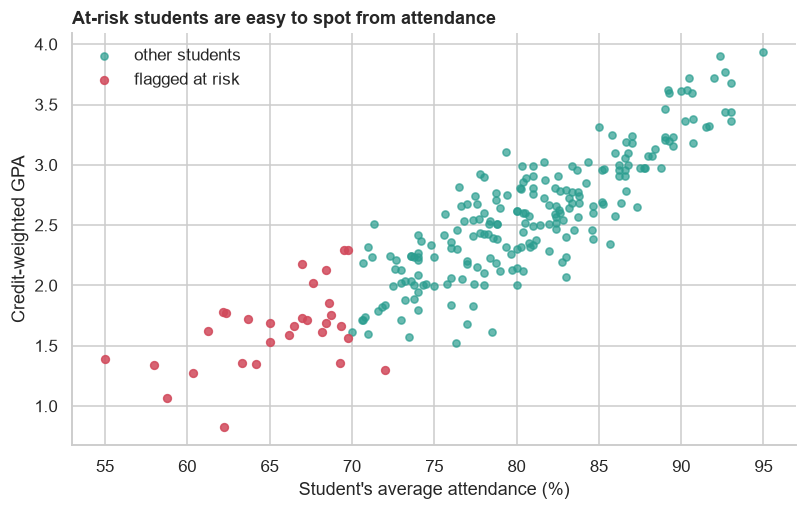

In [9]:
st = df.groupby(["student_id", "major"]).agg(courses=("grade", "size"), avg_attendance=("attendance_pct", "mean"),
        gpa=("grade_points", lambda x: np.average(x, weights=df.loc[x.index, "credits"])), fails=("failed", "sum")).reset_index()
st["at_risk"] = (st.avg_attendance < 70) | (st.fails >= 2)
print(f"{len(st)} students; {st.at_risk.sum()} flagged at risk ({st.at_risk.mean():.0%}): average attendance below 70% or two or more fails")
display(st.sort_values(["fails", "avg_attendance"], ascending=[False, True]).head(10).round(2))
print("credit-weighted GPA of all students:", round(st.gpa.mean(), 2), "| of at-risk students:", round(st[st.at_risk].gpa.mean(), 2), "| of the others:", round(st[~st.at_risk].gpa.mean(), 2))
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(st[~st.at_risk].avg_attendance, st[~st.at_risk].gpa, s=22, color="#2A9D8F", alpha=.7, label="other students")
ax.scatter(st[st.at_risk].avg_attendance, st[st.at_risk].gpa, s=26, color="#D1495B", alpha=.85, label="flagged at risk")
ax.set_xlabel("Student's average attendance (%)"); ax.set_ylabel("Credit-weighted GPA")
ax.set_title("At-risk students are easy to spot from attendance", loc="left", fontweight="bold"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(IMG + "06_students_at_risk.png", dpi=150); plt.show()

## 7. Conclusions

1. **Attendance explains outcomes far better than anything else in this data.** Spearman correlation with grade points is 0.85; credit hours (0.01) and gender (no significant difference) add nothing.
2. **Risk is concentrated and threshold-like.** An F appears only at 60% attendance or below; 42% of results at 61-70% are still a D or F; above 80% there are none. A simple rule (average attendance below 70%, or two fails) flags 30 of 244 students (12%) whose credit-weighted GPA is 1.64 against 2.59 for the rest.
3. **Majors do not differ significantly** (chi-square p = 0.34, Kruskal-Wallis p = 0.48). Biology has the highest fail rate and the lowest attendance, which is worth watching but not proven. Over time, average grade points slipped from 2.55 (Fall 2023) to 2.35 (Spring 2025) while attendance fell from 80% to 78%.
4. **Caveats.** This is sample course data, the relationships are observational (low attendance may be a symptom, not only a cause), and the grade-points column is fully determined by the letter grade.

**Next steps if this were a real project:** add prior GPA and course difficulty, build a logistic-regression early-warning model, and test an attendance intervention.